# k-nearest neighbours: stock style classifier

Part of the ML Portfolio Model Zoo. Educational purposes only.

Given a stock's P/E ratio, dividend yield and revenue growth, classify it as Value, Growth or Income by looking at the most similar stocks. The data is **synthetic**: three overlapping clusters.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

# Everything here reuses train.py, so the notebook and the site always use the same pipeline.

## Data

In [2]:
data = make_data()
print(data.shape)
data.head()

(3000, 4)


,pe_ratio,dividend_yield_pct,revenue_growth_pct,target
0,17.9,5.5,-0.6,2
1,22.7,0.5,21.3,1
2,15.5,6.2,6.9,2
3,38.8,0.8,20.4,1
4,18.8,0.1,4.6,0


In [3]:
data.describe(include='all').T

,count,mean,std,min,25%,50%,75%,max
pe_ratio,3000.0,21.328133,10.596299,3.0,14.0,18.6,26.2,68.2
dividend_yield_pct,3000.0,2.728833,1.825016,0.0,1.2,2.6,4.1,8.7
revenue_growth_pct,3000.0,9.983333,10.213599,-10.0,2.8,7.9,15.4,54.4
target,3000.0,0.922333,0.820889,0.0,0.0,1.0,2.0,2.0


## Train and evaluate

`train_and_evaluate()` fits the scikit-learn pipeline, scores it on a held-out split, exports it to ONNX and asserts that onnxruntime reproduces scikit-learn's predictions.

In [4]:
result = train_and_evaluate()
print(f"accuracy {result.metrics['accuracy']:.3f}   ROC AUC (one-vs-rest) {result.metrics['roc_auc']:.3f}")
print(f"majority-class baseline {result.metrics['majority_baseline']:.3f}")
print(f"ONNX vs sklearn max abs diff: {result.metrics['onnx_max_abs_diff']:.1e}")

accuracy 0.853   ROC AUC (one-vs-rest) 0.952
majority-class baseline 0.379
ONNX vs sklearn max abs diff: 2.8e-08


## Charts

The same charts the site shows, written to a temporary folder.

Held-out stocks by P/E and revenue growth. Value and Income overlap, Growth stands apart.


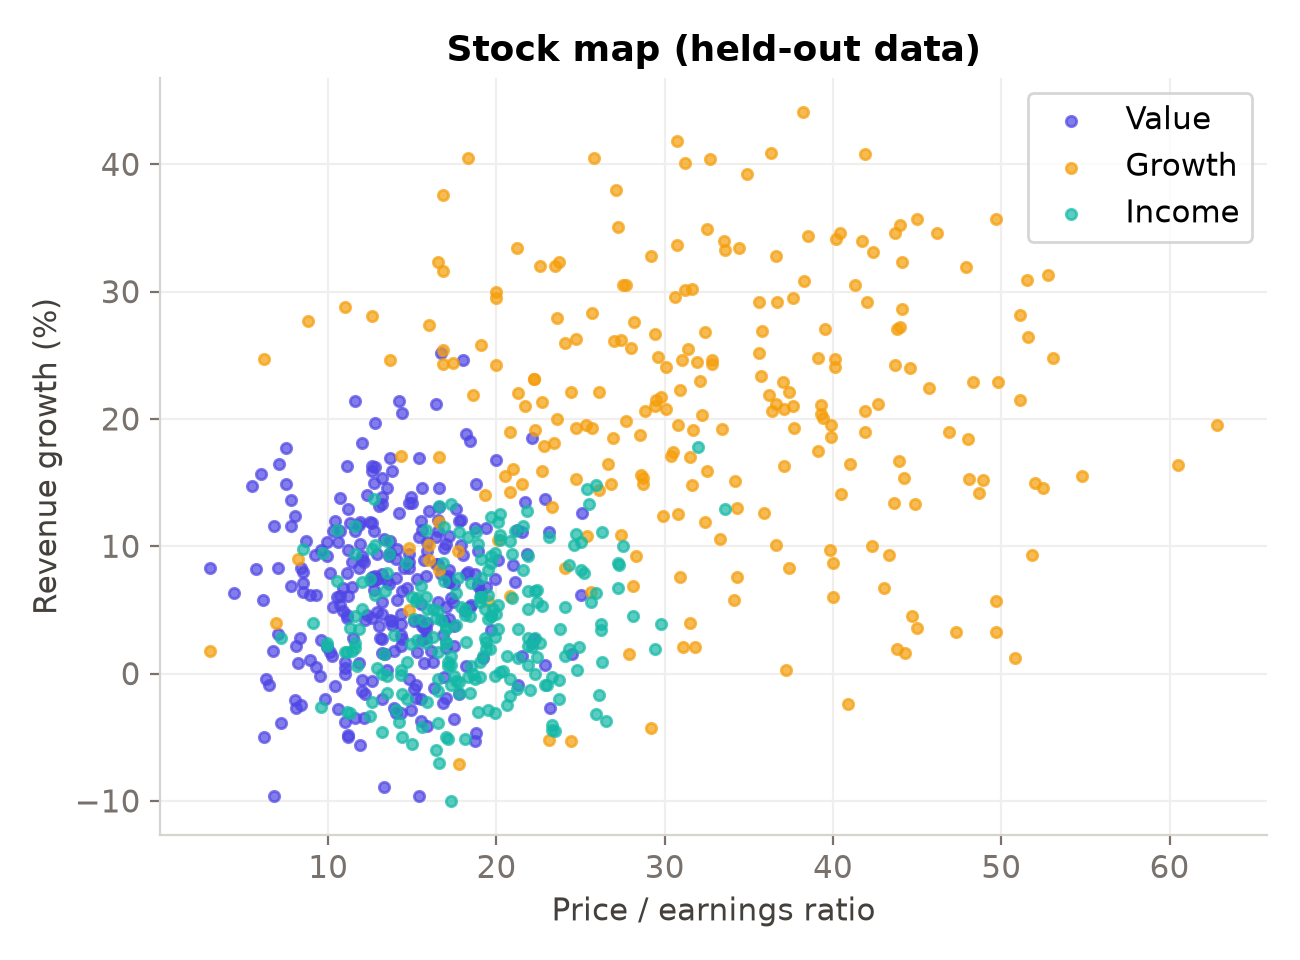

With k=1 the model memorises noise; a moderate k generalises better.


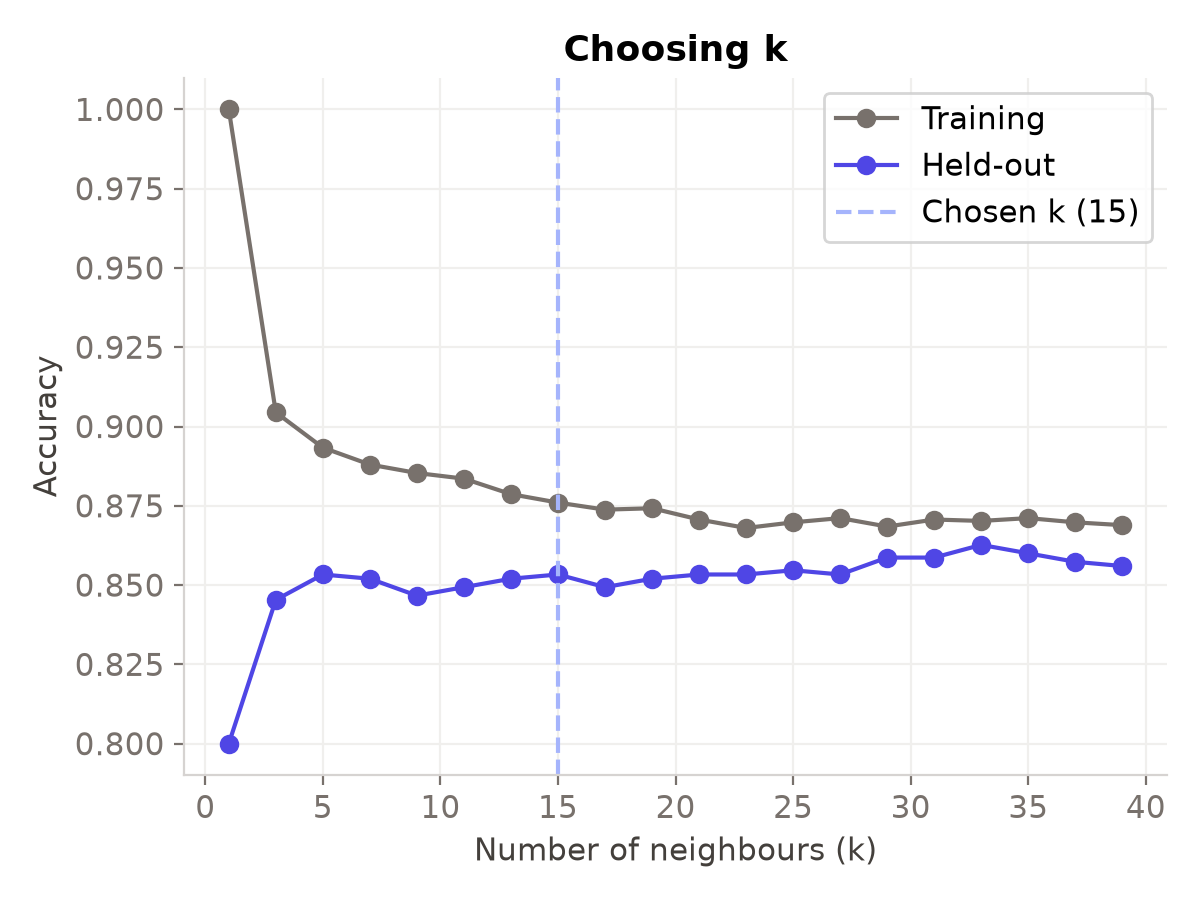

Confusion matrix on held-out data.


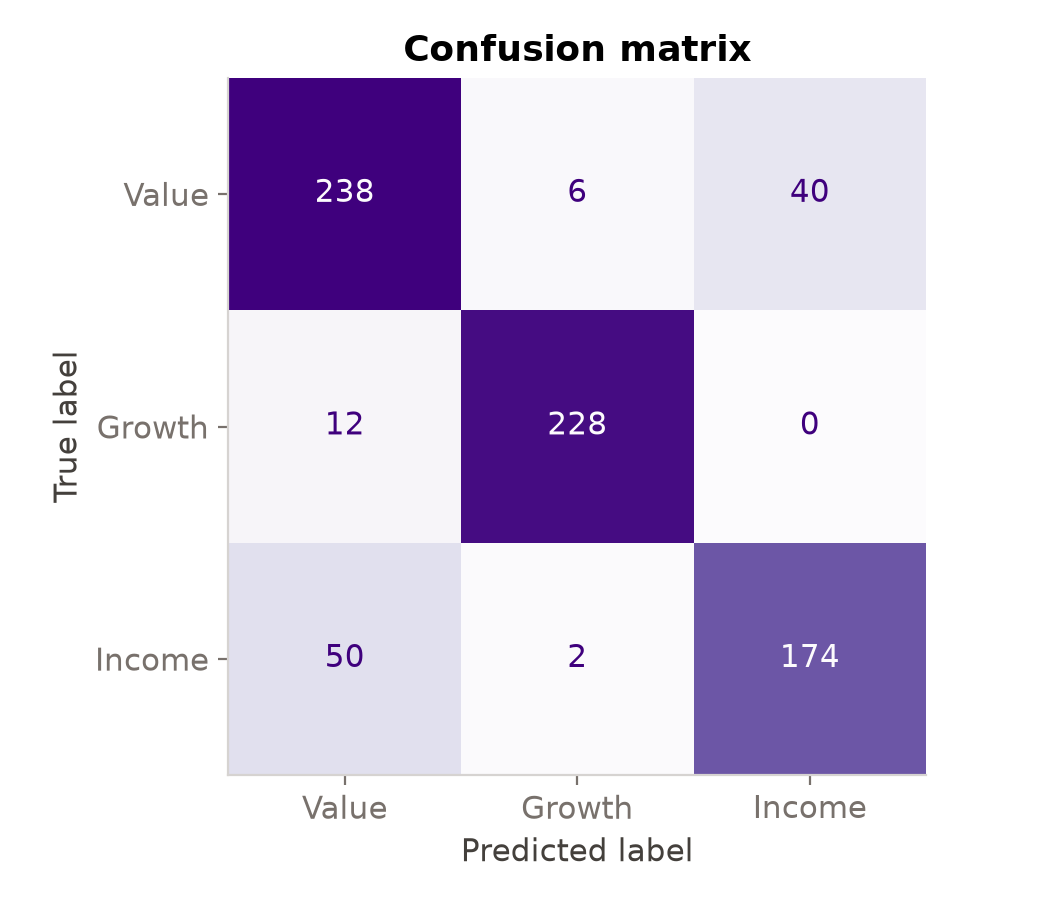

In [5]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## Predict with the exported ONNX model

In [6]:
example = pd.DataFrame([PRESETS[1]["values"]])[ALL_COLUMNS]
_, probs = onnx_predict(result.model_bytes, example)
print("High-growth preset ->", {l: f"{p:.0%}" for l, p in zip(LABELS, probs[0])})

High-growth preset -> {'Value': '0%', 'Growth': '100%', 'Income': '0%'}


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app. See the README for details.